In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical
import matplotlib.pyplot as plt

GAMMA = 0.99
EPISODES = 1000
SEEDS = [0, 1, 2]
torch.manual_seed(0)
np.random.seed(0)

In [2]:
class DeliveryEnv:
    vmax, steps, seg = 20.0, 100, 10     # max speed (m/s), steps per route, steps per segment
    accel_map = [-2.0, 0.0, 2.0]         # brake, maintain, accelerate (m/s^2)

    def __init__(self, seed=None):
        self.rng = np.random.default_rng(seed)

    def reset(self, seed=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        n = self.steps // self.seg
        # traffic: free (limit 20) or heavy (limit 10); road: flat (0) or uphill (1)
        self.limit = np.repeat(self.vmax * self.rng.choice([1.0, 0.5], n), self.seg)
        self.slope = np.repeat(self.rng.integers(0, 2, n), self.seg)
        self.t, self.v = 0, 0.0
        self.total_fuel, self.total_dist = 0.0, 0.0
        return self._obs()

    def _obs(self):
        t = min(self.t, self.steps - 1)
        ahead = min(t + 5, self.steps - 1)
        return np.array([self.v / self.vmax, self.limit[t] / self.vmax,
                         self.limit[ahead] / self.vmax, self.slope[t],
                         t / self.steps], dtype=np.float32)

    def step(self, action):
        limit, uphill = self.limit[self.t], self.slope[self.t]
        v_new = np.clip(self.v + self.accel_map[action], 0, self.vmax)
        acc = v_new - self.v

        # fuel: idle + air drag + acceleration + uphill
        fuel = (0.02 + 0.0005 * v_new**2 + 0.03 * max(acc, 0)
                + 0.1 * uphill * v_new / self.vmax)
        reward = v_new / self.vmax - fuel - 0.1 * max(v_new - limit, 0)

        self.v = v_new
        self.total_fuel += fuel
        self.total_dist += v_new
        self.t += 1
        return self._obs(), reward, self.t >= self.steps, {}

    def fuel_per_km(self):
        return self.total_fuel / max(self.total_dist / 1000, 0.1)

In [3]:
def evaluate(policy, n=50):
    fuel, speed, over, ret, dist = [], [], [], [], []
    env = DeliveryEnv()
    for i in range(n):
        s, done, total = env.reset(seed=10000 + i), False, 0.0
        speeds, overs = [], 0
        while not done:
            lim = env.limit[env.t]
            s, r, done, _ = env.step(policy(s))
            total += r
            speeds.append(env.v)
            overs += env.v > lim + 0.5
        fuel.append(env.fuel_per_km()); speed.append(np.mean(speeds))
        over.append(overs / env.steps * 100)
        ret.append(total); dist.append(env.total_dist / 1000)
    return {"Return": np.mean(ret), "Distance (km)": np.mean(dist),
            "Fuel (per km)": np.mean(fuel), "Avg speed (m/s)": np.mean(speed),
            "Overspeed (% steps)": np.mean(over)}

random_policy = lambda s: np.random.randint(3)

def cruise_policy(s):
    v, limit = s[0], s[1]
    return 2 if v < limit - 0.05 else (0 if v > limit + 0.02 else 1)

print("Random:", evaluate(random_policy))
print("Cruise:", evaluate(cruise_policy))

Random: {'Return': np.float64(17.899040000000003), 'Distance (km)': np.float64(0.69012), 'Fuel (per km)': np.float64(15.317160122091257), 'Avg speed (m/s)': np.float64(6.9012), 'Overspeed (% steps)': np.float64(11.7)}
Cruise: {'Return': np.float64(50.220000000000006), 'Distance (km)': np.float64(1.466), 'Fuel (per km)': np.float64(12.558853407853487), 'Avg speed (m/s)': np.float64(14.659999999999998), 'Overspeed (% steps)': np.float64(9.2)}


In [4]:
def mlp(inp, out, hidden=16):
    return nn.Sequential(nn.Linear(inp, hidden), nn.ReLU(), nn.Linear(hidden, out))

class SharedActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(5, 64), nn.Tanh(),
                                  nn.Linear(64, 64), nn.Tanh())
        self.pi = nn.Linear(64, 3)
        self.v = nn.Linear(64, 1)

    def forward(self, x):
        h = self.body(x)
        return self.pi(h), self.v(h).squeeze(-1)

In [5]:
def train_simple(episodes=EPISODES, seed=0):
    torch.manual_seed(seed)
    env = DeliveryEnv(seed)
    actor, critic = mlp(5, 3), mlp(5, 1)
    opt_c = torch.optim.AdamW(critic.parameters(), lr=1e-3)
    opt_a = torch.optim.AdamW(actor.parameters(), lr=1e-3)
    returns, fuels = [], []

    for ep in range(episodes):
        s, done = env.reset(), False
        states, actions, rewards = [], [], []
        while not done:
            with torch.no_grad():
                a = Categorical(logits=actor(torch.tensor(s))).sample().item()
            states.append(s)
            s, r, done, _ = env.step(a)
            actions.append(a); rewards.append(r)

        G, cum = 0.0, []
        for r in reversed(rewards):
            G = r + GAMMA * G
            cum.append(G)
        cum = torch.tensor(cum[::-1], dtype=torch.float32)
        states = torch.tensor(np.array(states))
        actions = torch.tensor(actions)

        vf_loss = F.mse_loss(critic(states).squeeze(1), cum, reduction="sum")
        opt_c.zero_grad(); vf_loss.backward(); opt_c.step()

        with torch.no_grad():
            adv = cum - critic(states).squeeze(1)
        log_probs = -F.cross_entropy(actor(states), actions, reduction="none")
        pi_loss = -(log_probs * adv).sum()
        opt_a.zero_grad(); pi_loss.backward(); opt_a.step()

        returns.append(sum(rewards)); fuels.append(env.fuel_per_km())
        if (ep + 1) % 100 == 0:
            print(f"Simple   seed {seed} ep {ep+1}: return {np.mean(returns[-100:]):.2f}, fuel/km {np.mean(fuels[-100:]):.2f}")
    return actor, returns, fuels

In [6]:
def train_advanced(episodes=EPISODES, seed=0, n_steps=50, lam=0.95, ent_coef=0.01):
    torch.manual_seed(seed)
    env = DeliveryEnv(seed)
    net = SharedActorCritic()
    opt = torch.optim.Adam(net.parameters(), lr=7e-4)
    returns, fuels = [], []

    for ep in range(episodes):
        s, done, total = env.reset(), False, 0.0
        while not done:
            logps, vals, rews, ents = [], [], [], []
            for _ in range(n_steps):                       # collect a short rollout
                logits, v = net(torch.tensor(s))
                dist = Categorical(logits=logits)
                a = dist.sample()
                s, r, done, _ = env.step(a.item())
                logps.append(dist.log_prob(a)); vals.append(v)
                rews.append(r); ents.append(dist.entropy())
                total += r
                if done:
                    break

            with torch.no_grad():
                next_v = 0.0 if done else net(torch.tensor(s))[1].item()

            adv, gae = [], 0.0                             # Generalized Advantage Estimation
            for t in reversed(range(len(rews))):
                delta = rews[t] + GAMMA * next_v - vals[t].item()
                gae = delta + GAMMA * lam * gae
                adv.append(gae); next_v = vals[t].item()
            adv = torch.tensor(adv[::-1], dtype=torch.float32)

            vals_t = torch.stack(vals)
            targets = adv + vals_t.detach()
            adv_norm = (adv - adv.mean()) / (adv.std() + 1e-8)

            loss = (-(torch.stack(logps) * adv_norm).mean()
                    + 0.5 * ((targets - vals_t) ** 2).mean()
                    - ent_coef * torch.stack(ents).mean())
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 0.5)
            opt.step()

        returns.append(total); fuels.append(env.fuel_per_km())
        if (ep + 1) % 100 == 0:
            print(f"Advanced seed {seed} ep {ep+1}: return {np.mean(returns[-100:]):.2f}, fuel/km {np.mean(fuels[-100:]):.2f}")
    return net, returns, fuels

In [7]:
runs = {"Simple AC": [], "Advanced AC": []}

for sd in SEEDS:
    runs["Simple AC"].append(train_simple(seed=sd))
    runs["Advanced AC"].append(train_advanced(seed=sd))

Simple   seed 0 ep 100: return 22.26, fuel/km 14.00
Simple   seed 0 ep 200: return 23.52, fuel/km 13.67
Simple   seed 0 ep 300: return 23.81, fuel/km 13.62
Simple   seed 0 ep 400: return 22.98, fuel/km 13.60
Simple   seed 0 ep 500: return 22.37, fuel/km 13.76
Simple   seed 0 ep 600: return 23.96, fuel/km 13.43
Simple   seed 0 ep 700: return 24.79, fuel/km 13.38
Simple   seed 0 ep 800: return 25.86, fuel/km 13.36
Simple   seed 0 ep 900: return 27.83, fuel/km 13.51
Simple   seed 0 ep 1000: return 28.50, fuel/km 13.37
Advanced seed 0 ep 100: return 22.01, fuel/km 14.31
Advanced seed 0 ep 200: return 25.26, fuel/km 13.62
Advanced seed 0 ep 300: return 27.48, fuel/km 13.55
Advanced seed 0 ep 400: return 27.77, fuel/km 13.64
Advanced seed 0 ep 500: return 26.63, fuel/km 13.82
Advanced seed 0 ep 600: return 27.14, fuel/km 13.66
Advanced seed 0 ep 700: return 29.38, fuel/km 13.61
Advanced seed 0 ep 800: return 32.51, fuel/km 13.77
Advanced seed 0 ep 900: return 33.24, fuel/km 13.73
Advanced se

In [8]:
simple_pol = lambda m: (lambda s: m(torch.tensor(s)).argmax().item())
adv_pol = lambda m: (lambda s: m(torch.tensor(s))[0].argmax().item())

rows = {
    "Simple AC": [evaluate(simple_pol(m)) for m, _, _ in runs["Simple AC"]],
    "Advanced AC": [evaluate(adv_pol(m)) for m, _, _ in runs["Advanced AC"]],
}
base = {"Random": evaluate(random_policy), "Cruise rule": evaluate(cruise_policy)}

In [9]:
mean_tbl = pd.DataFrame({**base, **{k: pd.DataFrame(v).mean() for k, v in rows.items()}}).T
std_tbl = (pd.DataFrame({k: pd.DataFrame(v).std() for k, v in rows.items()}).T
           .reindex(mean_tbl.index).fillna(0))

mean_tbl.round(2).astype(str) + " ± " + std_tbl.round(2).astype(str)

,Return,Distance (km),Fuel (per km),Avg speed (m/s),Overspeed (% steps)
Random,18.9 ± 0.0,0.66 ± 0.0,14.76 ± 0.0,6.56 ± 0.0,9.1 ± 0.0
Cruise rule,50.22 ± 0.0,1.47 ± 0.0,12.56 ± 0.0,14.66 ± 0.0,9.2 ± 0.0
Simple AC,25.83 ± 10.07,1.32 ± 0.81,12.7 ± 1.32,13.21 ± 8.13,27.03 ± 23.91
Advanced AC,21.29 ± 21.62,1.15 ± 1.01,15.66 ± 3.76,11.51 ± 10.14,23.0 ± 22.71


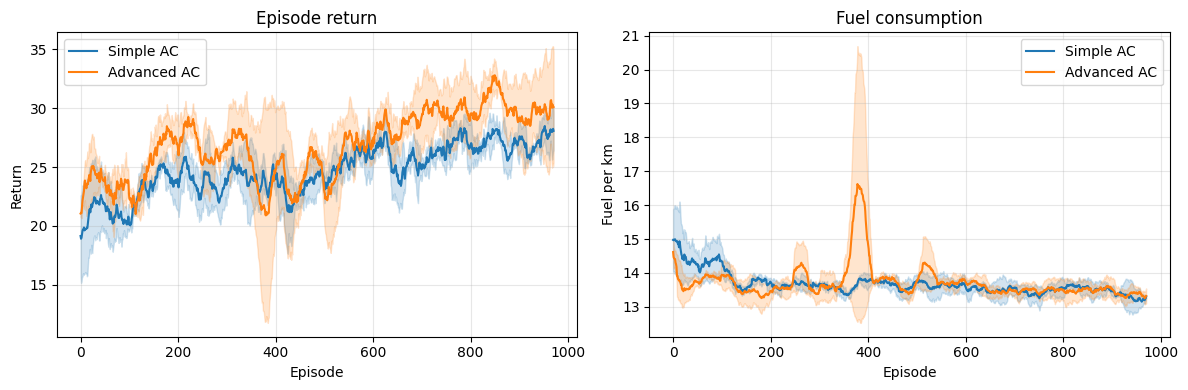

In [10]:
def smooth(x, k=30):
    return np.convolve(x, np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, color in [("Simple AC", "tab:blue"), ("Advanced AC", "tab:orange")]:
    for j, a in enumerate(ax):                      # j=0 returns, j=1 fuels
        data = np.array([smooth(run[1 + j]) for run in runs[name]])
        m, s = data.mean(0), data.std(0)
        a.plot(m, label=name, color=color)
        a.fill_between(range(len(m)), m - s, m + s, color=color, alpha=0.2)
ax[0].set(title="Episode return", xlabel="Episode", ylabel="Return")
ax[1].set(title="Fuel consumption", xlabel="Episode", ylabel="Fuel per km")
for a in ax:
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

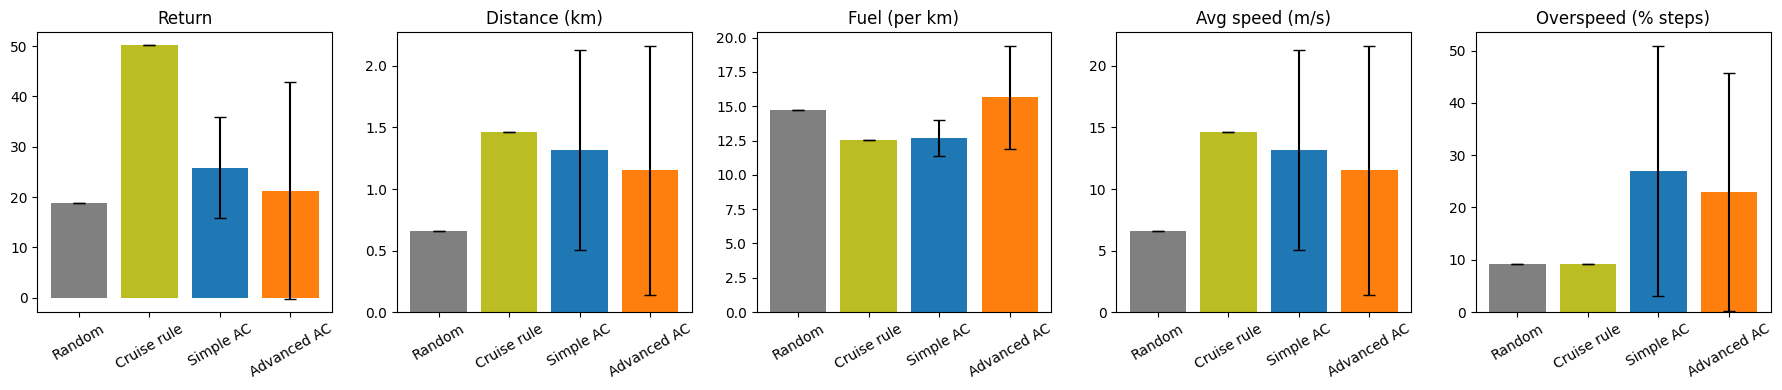

In [11]:
fig, ax = plt.subplots(1, len(mean_tbl.columns), figsize=(18, 4))
for a, col in zip(ax, mean_tbl.columns):
    a.bar(mean_tbl.index, mean_tbl[col], yerr=std_tbl[col],
          color=["gray", "tab:olive", "tab:blue", "tab:orange"], capsize=4)
    a.set_title(col); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

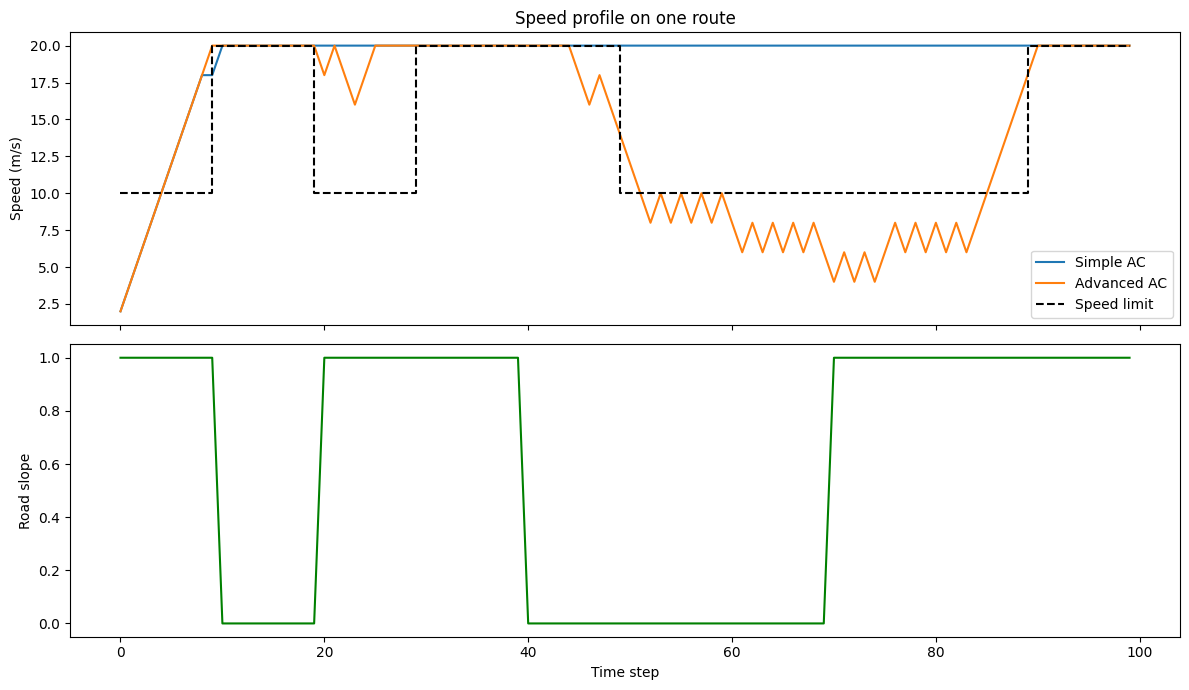

In [12]:
simple_policy = simple_pol(runs["Simple AC"][0][0])
adv_policy = adv_pol(runs["Advanced AC"][0][0])

def run_episode(policy, seed=12345):
    env = DeliveryEnv()
    s, done = env.reset(seed=seed), False
    speeds = []
    while not done:
        s, _, done, _ = env.step(policy(s))
        speeds.append(env.v)
    return speeds, env

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for name, pol in [("Simple AC", simple_policy), ("Advanced AC", adv_policy)]:
    speeds, env = run_episode(pol)
    ax[0].plot(speeds, label=name)
ax[0].step(range(env.steps), env.limit, "k--", label="Speed limit")
ax[0].set(ylabel="Speed (m/s)", title="Speed profile on one route"); ax[0].legend()
ax[1].plot(env.slope, color="green")
ax[1].set(ylabel="Road slope", xlabel="Time step")
plt.tight_layout(); plt.show()

In [13]:
gain = [a["Return"] - s["Return"] for a, s in zip(rows["Advanced AC"], rows["Simple AC"])]
print("Return gain of Advanced over Simple per seed:", np.round(gain, 2))
print("Mean gain:", round(np.mean(gain), 2))

Return gain of Advanced over Simple per seed: [ 14.4  -10.5  -17.53]
Mean gain: -4.54
